# Исследовательский анализ данных (EDA): исходы цирроза печени

Исследуем данные соревнования [Kaggle Playground Series S3E26](https://www.kaggle.com/competitions/playground-series-s3e26): структуру и качество таблиц, распределения признаков и целевой переменной, а также связи между ними. Анализ будет дополняться по мере работы над проектом. Исходные файлы: train.csv, test.csv, sample_submission.csv.

## Краткое описание признаков

Описание основано на [словаре исходного набора UCI](https://archive.ics.uci.edu/dataset/878/cirrhosis+patient+survival+prediction+dataset-1). Данные соревнования Kaggle синтетические, но названия признаков сохранены.

| Признак | Значение |
|---|---|
| id | Технический идентификатор строки. |
| N_Days | Число дней от включения в исследование до смерти, трансплантации или окончания наблюдения. |
| Drug | Назначенный препарат: D-пеницилламин или плацебо. |
| Age | Возраст пациента в днях. |
| Sex | Пол: F — женский, M — мужской. |
| Ascites | Наличие асцита (жидкости в брюшной полости): Y/N. |
| Hepatomegaly | Увеличение печени: Y/N. |
| Spiders | Сосудистые "звёздочки": Y/N. |
| Edema | Отёки: N — нет, S — есть без мочегонных или исчезают на их фоне, Y — сохраняются несмотря на мочегонные. |
| Bilirubin | Билирубин в сыворотке крови, мг/дл. |
| Cholesterol | Холестерин в сыворотке крови, мг/дл. |
| Albumin | Альбумин в сыворотке крови, г/дл. |
| Copper | Медь в моче, мкг/сутки. |
| Alk_Phos | Щелочная фосфатаза, Ед/л. |
| SGOT | Фермент SGOT (АСТ), Ед/мл согласно исходному словарю. |
| Tryglicerides | Триглицериды, мг/дл; написание столбца сохранено как в файле. |
| Platelets | Количество тромбоцитов. |
| Prothrombin | Протромбиновое время, секунды. |
| Stage | Гистологическая стадия заболевания: 1–4. |
| Status | Целевой исход: C — наблюдение завершено при живом пациенте; CL — наблюдение цензурировано из-за трансплантации; D — смерть. |

## 1. Цель проекта и показатели эффективности

**Цель:** по табличным признакам пациента с циррозом предсказать вероятности трёх значений Status:

- C — пациент жив на момент N_Days (наблюдение цензурировано);
- CL — пациент жив после трансплантации печени;
- D — пациент умер к моменту N_Days.

Это **многоклассовая классификация**. Для каждой строки теста нужны три вероятности: Status_C, Status_CL, Status_D.

**Основная метрика соревнования — multiclass log loss** (чем меньше, тем лучше). Она оценивает качество *вероятностей* и сильно штрафует уверенные ошибочные прогнозы. Формула: $-\frac{1}{N}\sum_i\sum_j y_{ij}\log(p_{ij})$. При локальной проверке будем использовать стратифицированную кросс-валидацию и считать средний log loss со стандартным отклонением между фолдами. Предсказания для каждого пациента должны суммироваться до 1.

**Дополнительные диагностические метрики:** accuracy, macro F1, recall по каждому классу и матрица ошибок. Они помогают понять, как модель работает с редким CL, но не заменяют основную метрику. Для начала полезно сравнить будущие модели с базовым прогнозом по частотам классов на обучающей части каждого фолда.

**Ограничение постановки:** N_Days отражает длительность наблюдения. Признак дан в тесте Kaggle, но для реального прогноза на момент первичного осмотра его доступность нужно отдельно обосновать. Данные синтетические, результаты соревнования нельзя напрямую трактовать как клиническую точность.

## 2. Загрузка данных и первичный осмотр

### 2.1 Загрузка данных

Загружаем исходные CSV без изменения значений. id — идентификатор строки, целевой признак Status есть только в train. Пути ищутся относительно расположения ноутбука или текущей рабочей папки.


In [1]:
# Импорты
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik

# Глобальные настройки отображения
pd.set_option('display.float_format', lambda x: f'{x:.2f}')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})

# Глобальные константы 
CLASSES = ['C', 'CL', 'D']

# Структура репозитория: notebooks/eda_uno.ipynb и data/raw/*.csv.
# Поддерживаем запуск из корня проекта и из папки notebooks.
current_dir = Path.cwd()
project_root = current_dir if (current_dir / "data" / "raw" / "train.csv").exists() else current_dir.parent
data_dir = project_root / "data" / "raw"
if not (data_dir / "train.csv").exists():
    raise FileNotFoundError("Не найден data/raw/train.csv. Запустите ноутбук из корня проекта или папки notebooks.")

train = pd.read_csv(data_dir / "train.csv")
test = pd.read_csv(data_dir / "test.csv")
submission_example = pd.read_csv(data_dir / "sample_submission.csv")

print(f"train: {train.shape[0]} строк × {train.shape[1]} столбцов")
print(f"test: {test.shape[0]} строк × {test.shape[1]} столбцов")
print(f"sample_submission: {submission_example.shape[0]} строк × {submission_example.shape[1]} столбца")

train: 7905 строк × 20 столбцов
test: 5271 строк × 19 столбцов
sample_submission: 5271 строк × 4 столбца


### 2.2 Первые строки и типы признаков

Первые строки показывают формат данных. info() помогает проверить типы столбцов и количество непустых значений.

In [2]:
print(train.head(5).to_string())
train.info()

   id  N_Days             Drug    Age Sex Ascites Hepatomegaly Spiders Edema  Bilirubin  Cholesterol  Albumin  Copper  Alk_Phos   SGOT  Tryglicerides  Platelets  Prothrombin  Stage Status
0   0     999  D-penicillamine  21532   M       N            N       N     N       2.30       316.00     3.35  172.00   1601.00 179.80          63.00     394.00         9.70   3.00      D
1   1    2574          Placebo  19237   F       N            N       N     N       0.90       364.00     3.54   63.00   1440.00 134.85          88.00     361.00        11.00   3.00      C
2   2    3428          Placebo  13727   F       N            Y       Y     Y       3.30       299.00     3.55  131.00   1029.00 119.35          50.00     199.00        11.70   4.00      D
3   3    2576          Placebo  18460   F       N            N       N     N       0.60       256.00     3.50   58.00   1653.00  71.30          96.00     269.00        10.70   3.00      C
4   4     788          Placebo  16658   F       N           

### 2.3 Описательная статистика (describe)

Для числовых признаков смотрим количество значений, среднее, стандартное отклонение, квартили и крайние значения. Для категориальных — количество уникальных значений, самый частый вариант и его частоту. id — технический идентификатор, поэтому исключаем его из статистики признаков.

In [3]:
numeric_features = train.select_dtypes(include="number").drop(columns="id")
print(numeric_features.describe().T.to_string())

                count     mean     std     min      25%      50%      75%      max
N_Days        7905.00  2030.17 1094.23   41.00  1230.00  1831.00  2689.00  4795.00
Age           7905.00 18373.15 3679.96 9598.00 15574.00 18713.00 20684.00 28650.00
Bilirubin     7905.00     2.59    3.81    0.30     0.70     1.10     3.00    28.00
Cholesterol   7905.00   350.56  195.38  120.00   248.00   298.00   390.00  1775.00
Albumin       7905.00     3.55    0.35    1.96     3.35     3.58     3.77     4.64
Copper        7905.00    83.90   75.90    4.00    39.00    63.00   102.00   588.00
Alk_Phos      7905.00  1816.75 1903.75  289.00   834.00  1181.00  1857.00 13862.40
SGOT          7905.00   114.60   48.79   26.35    75.95   108.50   137.95   457.25
Tryglicerides 7905.00   115.34   52.53   33.00    84.00   104.00   139.00   598.00
Platelets     7905.00   265.23   87.47   62.00   211.00   265.00   316.00   563.00
Prothrombin   7905.00    10.63    0.78    9.00    10.00    10.60    11.00    18.00
Stag

Отрицательных или нулевых значений в возрасте, длительности наблюдения и лабораторных показателях в train не обнаружено. Это исключает часть очевидных ошибок ввода, однако само по себе не подтверждает клиническую допустимость всех значений. Экстремальные наблюдения дополнительно рассмотрены по распределениям и правилу IQR.

In [4]:
categorical_features = train.select_dtypes(exclude="number")
print(categorical_features.describe().T.to_string())

             count unique      top  freq
Drug          7905      2  Placebo  4010
Sex           7905      2        F  7336
Ascites       7905      2        N  7525
Hepatomegaly  7905      2        Y  4042
Spiders       7905      2        N  5966
Edema         7905      3        N  7161
Status        7905      3        C  4965


### 2.4 Структура train и test

Проверяем, что тест отличается от обучающей выборки только отсутствием целевой переменной, а идентификаторы уникальны.

In [5]:
feature_columns = [column for column in train.columns if column != "Status"]
print("Признаки train и столбцы test совпадают:", feature_columns == list(test.columns))
print("Уникальные id в train:", train["id"].is_unique)
print("Уникальные id в test:", test["id"].is_unique)
print("Пересечение id train/test:", len(set(train["id"]) & set(test["id"])))
print("Столбцы файла отправки:", submission_example.columns.tolist())

Признаки train и столбцы test совпадают: True
Уникальные id в train: True
Уникальные id в test: True
Пересечение id train/test: 0
Столбцы файла отправки: ['id', 'Status_C', 'Status_CL', 'Status_D']


## 3. Анализ и обработка пропусков

Сначала считаем настоящие NaN/None. Отдельно проверяем пустые и состоящие из пробелов строки в текстовых столбцах: pandas может не считать их пропусками. Проверки проводим на train и test по отдельности.

In [6]:
def missing_report(frame):
    # В одном отчёте объединяем стандартные пропуски и пустой текст.
    text_columns = frame.select_dtypes(include=["object", "string"]).columns
    missing_mask = frame.isna().copy()
    for column in text_columns:
        missing_mask[column] |= frame[column].astype("string").str.strip().eq("").fillna(False)
    report = pd.DataFrame({
        "Пропусков": missing_mask.sum(),
        "Доля, %": missing_mask.mean().mul(100).round(2),
    })
    return report.sort_values("Пропусков", ascending=False), int(missing_mask.any(axis=1).sum())

for name, frame in [("train", train), ("test", test)]:
    report, rows_with_missing = missing_report(frame)
    print(f"{name}: строк с хотя бы одним пропуском — {rows_with_missing}; всего пропусков — {report['Пропусков'].sum()}")
    print(report.to_string())

train: строк с хотя бы одним пропуском — 0; всего пропусков — 0
               Пропусков  Доля, %
id                     0     0.00
N_Days                 0     0.00
Drug                   0     0.00
Age                    0     0.00
Sex                    0     0.00
Ascites                0     0.00
Hepatomegaly           0     0.00
Spiders                0     0.00
Edema                  0     0.00
Bilirubin              0     0.00
Cholesterol            0     0.00
Albumin                0     0.00
Copper                 0     0.00
Alk_Phos               0     0.00
SGOT                   0     0.00
Tryglicerides          0     0.00
Platelets              0     0.00
Prothrombin            0     0.00
Stage                  0     0.00
Status                 0     0.00
test: строк с хотя бы одним пропуском — 0; всего пропусков — 0
               Пропусков  Доля, %
id                     0     0.00
N_Days                 0     0.00
Drug                   0     0.00
Age                    

### Решение по обработке

В текущих файлах пропусков и пустых текстовых значений нет, поэтому удаление строк или заполнение значений **не требуется**. Исходные CSV сохраняем без изменений. Если пропуски появятся в новых данных, способ заполнения нужно выбирать по смыслу признака и обучать его только на тренировочной части каждого фолда, чтобы не допустить утечки информации.

## 4. Поиск аномалий и обработка выбросов

### 4.1 Анализ выбросов

In [7]:
def get_margins_from_col(df):
  iqr = df.quantile(0.75) - df.quantile(0.25)
  left =  max(df.quantile(0.25) - 1.5 * iqr, df.min())
  right = min(df.quantile(0.75) + 1.5 * iqr, df.max())
  return (left, right)

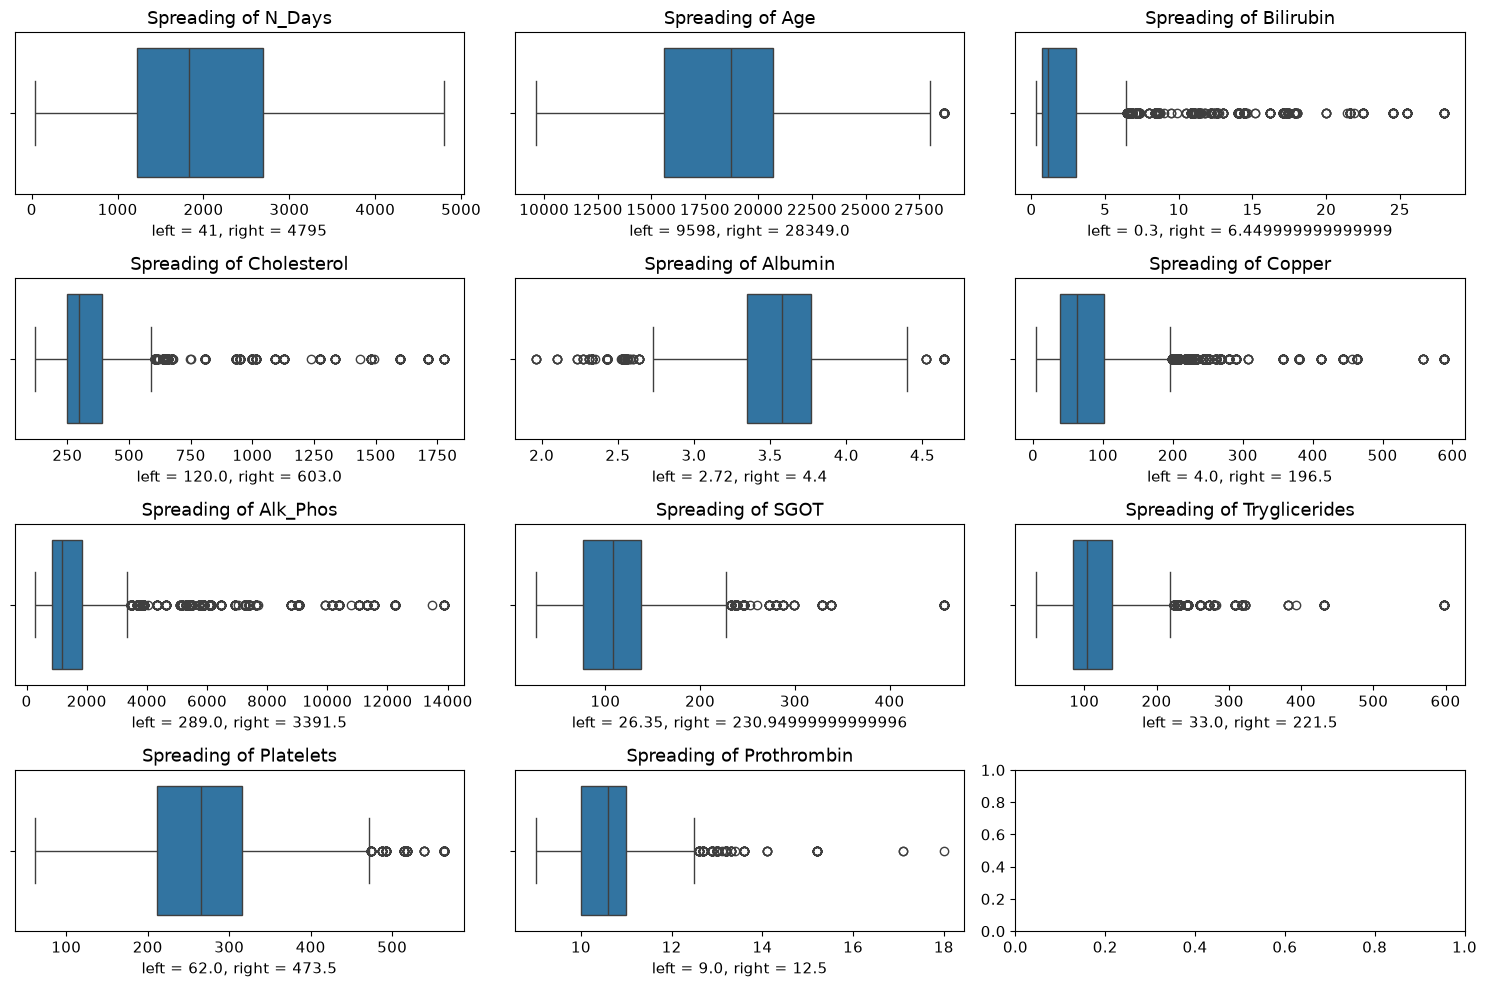

In [8]:
numeric_cols = [
    c for c in train.select_dtypes(include="number").columns
    if c not in {"id", "Stage"}
]

fig, axes = plt.subplots(int(np.ceil(len(numeric_cols)/3)),3, figsize=(15,10))
axes = axes.flatten()
for i, col in enumerate(train[numeric_cols]):
  left, right = get_margins_from_col(train[col])

  sns.boxplot(data=train, x=col, ax=axes[i])
  axes[i].set_title(f'Spreading of {col}')
  axes[i].set_xlabel(f'left = {left}, right = {right}')
plt.tight_layout()
plt.show()

* У ряда лабораторных показателей есть значения далеко за пределами основной массы наблюдений.
* У Bilirubin, Cholesterol, Alk_Phos, Copper и Tryglicerides выражена правая асимметрия: средние выше медиан, распределения имеют длинные правые хвосты.
* Возраст в исходном файле указан в днях; распределение возраста в годах показано ниже в разделе 5.
* Albumin имеет левую асимметрию. Связь низких значений с исходом рассмотрим отдельно.
* По правилу 1,5 × IQR выше верхней границы находятся 792 наблюдения для Alk_Phos и 789 для Bilirubin. Само правило помечает статистически редкие значения, но не доказывает ошибку измерения.
* Экстремальные значения пока сохраняем: оснований автоматически удалять их по одному лишь boxplot нет.

Проверяем гипотезу, что отклонения связаны с тяжелым состоянием пациента

In [9]:
test_df = train[numeric_cols].drop(columns=['N_Days', 'Age'])
results = []

for col in test_df:
  left, right = get_margins_from_col(train[col])
  filtered_df = train[train[col] > right]
  counts =  filtered_df.groupby('Status', observed=False).size().reindex(['C', 'CL', 'D'], fill_value=0)
  counts_sum = counts.sum()

  results.append({
      'Feature': col,
      'Total_patients': counts_sum,
      'C': counts['C'],
      'C_percent': round((counts['C'] / counts_sum * 100), 1) if counts_sum > 0 else 0,
      'CL': counts['CL'],
      'CL_percent': round((counts['CL'] / counts_sum * 100), 1) if counts_sum > 0 else 0,
      'D': counts['D'],
      'D_percent': round((counts['D'] / counts_sum * 100), 1) if counts_sum > 0 else 0
  })

results = pd.DataFrame(results)
display(results.sort_values(by='D_percent', ascending=False))


,Feature,Total_patients,C,C_percent,CL,CL_percent,D,D_percent
0,Bilirubin,789,137,17.40,17,2.20,635,80.50
8,Prothrombin,173,32,18.50,2,1.20,139,80.30
3,Copper,655,132,20.20,17,2.60,506,77.30
1,Cholesterol,502,169,33.70,19,3.80,314,62.50
6,Tryglicerides,267,90,33.70,12,4.50,165,61.80
5,SGOT,146,58,39.70,4,2.70,84,57.50
4,Alk_Phos,792,358,45.20,25,3.20,409,51.60
7,Platelets,114,67,58.80,2,1.80,45,39.50
2,Albumin,25,25,100.00,0,0.00,0,0.00


Сравнение долей Status в группах выше границы IQR позволяет оценить связь высоких значений показателей с исходом в этой выборке. Такая связь не доказывает причину исхода.

Проверим выбросы ниже iQR

In [10]:
test_df = train[numeric_cols].drop(columns=['N_Days', 'Age'])
results = []

for col in test_df:
  left, right = get_margins_from_col(train[col])
  filtered_df = train[train[col] < left]
  counts =  filtered_df.groupby('Status', observed=False).size().reindex(['C', 'CL', 'D'], fill_value=0)
  counts_sum = counts.sum()

  results.append({
      'Feature': col,
      'Total_patients': counts_sum,
      'C': counts['C'],
      'C_percent': round((counts['C'] / counts_sum * 100), 1) if counts_sum > 0 else 0,
      'CL': counts['CL'],
      'CL_percent': round((counts['CL'] / counts_sum * 100), 1) if counts_sum > 0 else 0,
      'D': counts['D'],
      'D_percent': round((counts['D'] / counts_sum * 100), 1) if counts_sum > 0 else 0
  })

results = pd.DataFrame(results)
display(results.sort_values(by='D_percent', ascending=False))

,Feature,Total_patients,C,C_percent,CL,CL_percent,D,D_percent
2,Albumin,153,12,7.80,1,0.70,140,91.50
0,Bilirubin,0,0,0.00,0,0.00,0,0.00
1,Cholesterol,0,0,0.00,0,0.00,0,0.00
3,Copper,0,0,0.00,0,0.00,0,0.00
4,Alk_Phos,0,0,0.00,0,0.00,0,0.00
5,SGOT,0,0,0.00,0,0.00,0,0.00
6,Tryglicerides,0,0,0.00,0,0.00,0,0.00
7,Platelets,0,0,0.00,0,0.00,0,0.00
8,Prothrombin,0,0,0.00,0,0.00,0,0.00


Проверим гипотезу о связи низкого Albumin с исходом и отдельно посмотрим пациентов, у которых низкий альбумин сочетается с высокими значениями других показателей.

In [11]:
train[
    (train['Albumin'] < get_margins_from_col(train['Albumin'])[0])
    & (train['Bilirubin'] > get_margins_from_col(train['Bilirubin'])[1])
    & (train['Prothrombin'] > get_margins_from_col(train['Prothrombin'])[1])
    & (train['Copper'] > get_margins_from_col(train['Copper'])[1])
]

,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
3197,3197,1478,D-penicillamine,15177,F,Y,N,Y,Y,17.10,151.00,2.54,207.00,1257.00,119.35,70.00,139.00,12.70,4.00,D
4598,4598,191,D-penicillamine,21483,F,Y,Y,Y,Y,17.90,243.00,2.33,220.00,3196.00,155.00,154.00,165.00,12.60,4.00,D
7642,7642,264,D-penicillamine,20555,F,N,Y,Y,Y,17.40,175.00,2.10,220.00,705.00,338.00,229.00,62.00,12.90,4.00,D


В выбранную группу попали 3 пациента, и у всех указан `Status = D`. Группа слишком мала для общего вывода о риске. Экстремальные значения пока сохраняем: одного отклонения от границ IQR недостаточно, чтобы признать запись ошибочной.

### 4.2 Анализ дубликатов

In [12]:
train.duplicated().sum()

np.int64(0)

Поскольку id есть у всех и уникально, уберем его и проверим частичные дубликаты

In [13]:
train.drop(columns=['id']).duplicated().sum()

np.int64(0)

Удалим колонку id поскольку она является техническим полем и не несет никакой полезной информации

In [14]:
train_clear = train.drop(columns=['id']).reset_index(drop=True)
train_clear.info()

<class 'pandas.DataFrame'>
RangeIndex: 7905 entries, 0 to 7904
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   N_Days         7905 non-null   int64  
 1   Drug           7905 non-null   str    
 2   Age            7905 non-null   int64  
 3   Sex            7905 non-null   str    
 4   Ascites        7905 non-null   str    
 5   Hepatomegaly   7905 non-null   str    
 6   Spiders        7905 non-null   str    
 7   Edema          7905 non-null   str    
 8   Bilirubin      7905 non-null   float64
 9   Cholesterol    7905 non-null   float64
 10  Albumin        7905 non-null   float64
 11  Copper         7905 non-null   float64
 12  Alk_Phos       7905 non-null   float64
 13  SGOT           7905 non-null   float64
 14  Tryglicerides  7905 non-null   float64
 15  Platelets      7905 non-null   float64
 16  Prothrombin    7905 non-null   float64
 17  Stage          7905 non-null   float64
 18  Status         7905

Проверка показала, что в датасете присутствует ровно 0 дубликатов. Все наблюдения в таблице уникальны. Технический столбец id не несет аналитической нагрузки, поэтому для дальнейшего анализа будет создан датасет train_clear — копию обучающей таблицы без технического идентификатора id. Исходные train и test сохраняем без изменений.

## 5. Анализ распределения признаков

### 5.1 Анализ категориальных признаков

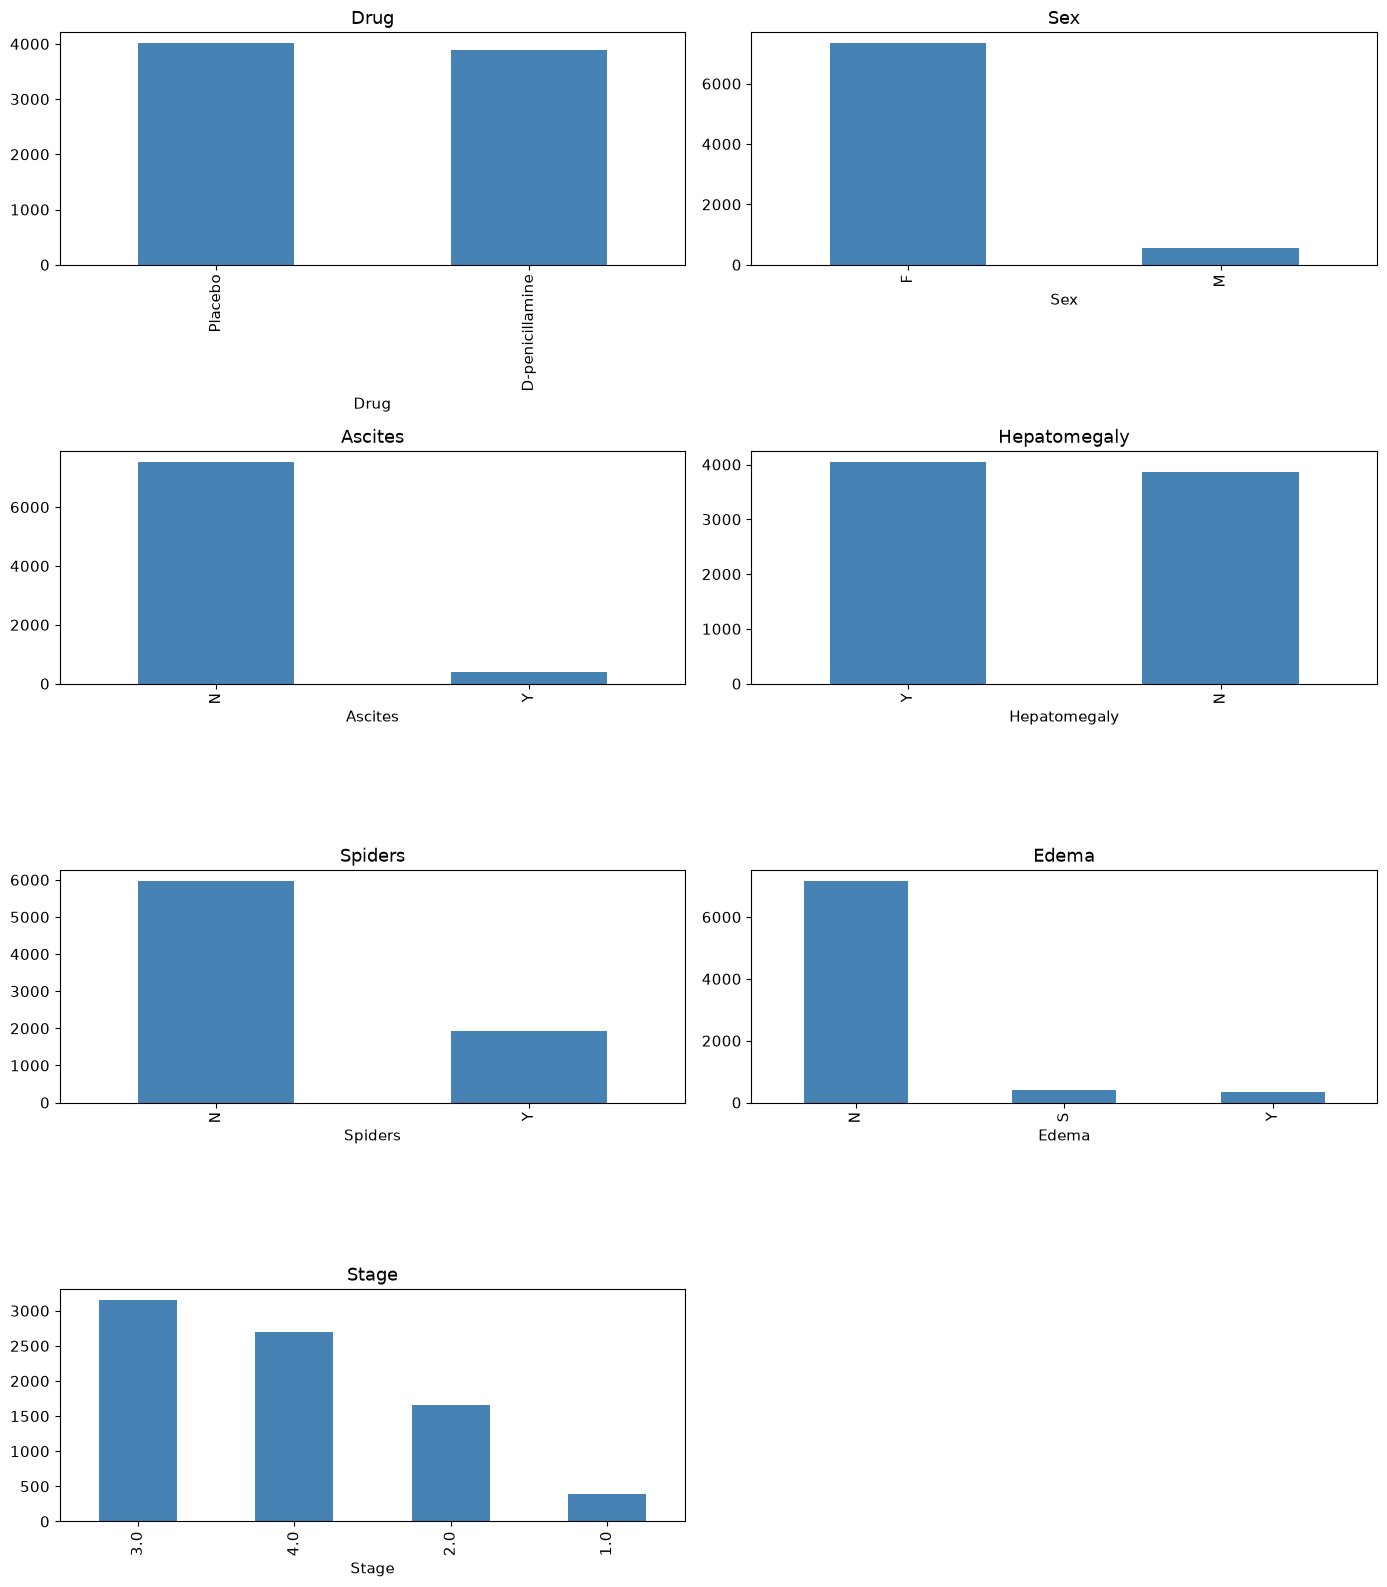

,Признак,Распределение долей
0,Drug,"Placebo: 50.73%, D-penicillamine: 49.27%"
1,Sex,"F: 92.8%, M: 7.2%"
2,Ascites,"N: 95.19%, Y: 4.81%"
3,Hepatomegaly,"Y: 51.13%, N: 48.87%"
4,Spiders,"N: 75.47%, Y: 24.53%"
5,Edema,"N: 90.59%, S: 5.05%, Y: 4.36%"
6,Stage,"3.0: 39.89%, 4.0: 34.19%, 2.0: 20.9%, 1.0: 5.02%"


In [15]:
CAT_FEATS = ["Drug", "Sex", "Ascites", "Hepatomegaly", "Spiders", "Edema", "Stage"]

n = len(CAT_FEATS)
fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(14, 4 * ((n + 1) // 2)))
axes = axes.flatten()
for ax, col in zip(axes, CAT_FEATS):
    train_clear[col].value_counts().plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(col)
for ax in axes[n:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

cat_shares = []
for col in CAT_FEATS:
    shares = (train_clear[col].value_counts(normalize=True) * 100).round(2)
    dist_str = ", ".join([f"{k}: {v}%" for k, v in shares.items()])
    cat_shares.append({"Признак": col, "Распределение долей": dist_str})

display(pd.DataFrame(cat_shares))

* `Drug`: доли плацебо и D-пеницилламина близки (50,7% и 49,3%). По одному распределению лечения нельзя судить о его связи с исходом.
* `Sex`: женщины составляют 92,8% выборки, мужчины — 7,2%. Из-за небольшой мужской подгруппы качество модели для неё стоит оценивать отдельно.
* `Ascites=Y` встречается у 4,8% пациентов. Связь этого признака с исходом проверим в двумерном анализе и при моделировании.
* `Hepatomegaly=Y` встречается у 51,1%, `Spiders=Y` — у 24,5% пациентов.
* `Edema` имеет три уровня: N — 90,6%, S — 5,0%, Y — 4,4%. Способ кодирования следует сравнить при моделировании.
* `Stage` принимает значения от 1 до 4 и описывает порядковую стадию заболевания.

### 5.2 Анализ числовых признаков

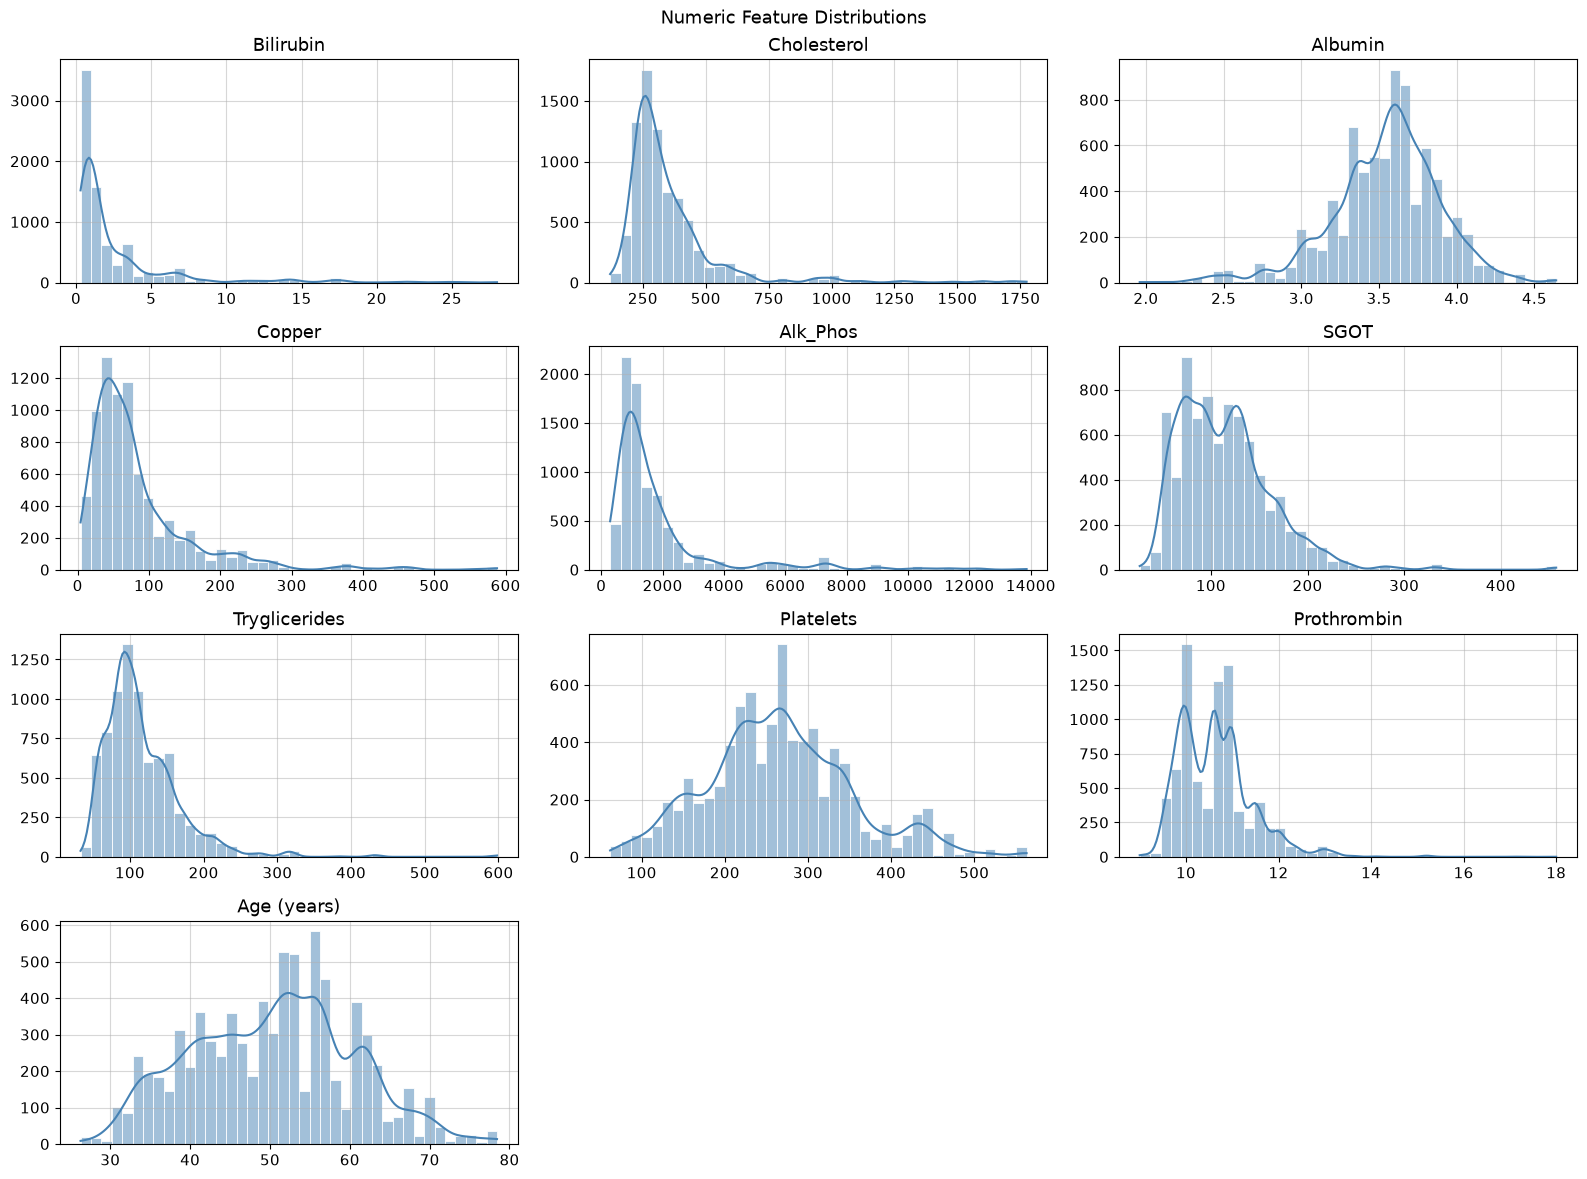

In [16]:
# Числовые признаки: гистограмма и сглаженная линия распределения (KDE).
clean_num_feats = [
    column for column in train_clear.select_dtypes(include="number").columns
    if column not in {"Stage", "Age", "N_Days"}
]
hist_data = train_clear[clean_num_feats].copy()
# Возраст переводим в годы только для графика, не изменяя исходный Age.
hist_data["Age (years)"] = train_clear["Age"] / 365.25

columns = hist_data.columns
fig, axes = plt.subplots(4, 3, figsize=(16, 12))
for ax, column in zip(axes.flat, columns):
    sns.histplot(hist_data[column], bins=40, kde=True, ax=ax,
                 color="steelblue", edgecolor="white")
    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(True, alpha=0.5)
for ax in list(axes.flat)[len(columns):]:
    ax.set_visible(False)
fig.suptitle("Numeric Feature Distributions")
plt.tight_layout()
plt.show()

* У Bilirubin, Cholesterol, Alk_Phos, Copper и Tryglicerides видны длинные правые хвосты. Для моделирования можно проверить преобразования этих признаков.
* Возраст после перевода из дней в годы лежит примерно в диапазоне 26–78 лет. Гистограмма показывает распределение непосредственно, без округления возраста до целых лет.
* У Albumin заметен левый хвост; возможную связь низких значений с `Status` проверяем отдельно.
* Значения за пределами 1,5 × IQR оставляем в данных до проверки их влияния на качество модели и возможных ошибок ввода.

## 6. Исследование баланса целевой переменной Status

### 6.1 Значения целевой переменной и верификация данных

**Цель:** определить численность и доли классов исходов, оценить дисбаланс и сформулировать рекомендации по разбиению данных и оценке моделей.

Источник: Анализ проводится по исходному `train.csv`, до балансировки или иных преобразований. Данные соревнования синтетические: доли характеризуют эту выборку, а не клиническую популяцию.

| Класс | Интерпретация по описанию соревнования |
|---|---|
| C | Пациент жив на момент N_Days; наблюдение цензурировано |
| CL | Пациент жив на момент N_Days после трансплантации печени |
| D | Пациент умер к моменту N_Days |

Класс C не означает выздоровление или гарантированное дальнейшее выживание. Статусы относятся к сроку наблюдения N_Days и не задают единый горизонт прогноза, например один год. 

Проверяем пропуски и допустимые значения. Неожиданные метки не исправляются автоматически: сначала нужно установить их происхождение. При проблемах расчёт останавливается, чтобы не получить неверные доли.

In [17]:
target = train_clear['Status']
missing = int(target.isna().sum())
unexpected = target[target.notna() & ~target.isin(CLASSES)]
print('Тип данных:', target.dtype)
print('Уникальные значения:', target.unique().tolist())
print('Пропуски:', missing)
print('Неожиданные метки:', unexpected.unique().tolist())
if len(train) == 0:
    raise ValueError('Выборка пуста.')
if missing or len(unexpected):
    raise ValueError('Сначала разберите пропуски или неожиданные метки Status.')
if not set(CLASSES).issubset(set(target)):
    raise ValueError('Один из трёх ожидаемых классов отсутствует.')
print('Проверка пройдена: все статусы заполнены и соответствуют описанию.')

Тип данных: str
Уникальные значения: ['D', 'C', 'CL']
Пропуски: 0
Неожиданные метки: []
Проверка пройдена: все статусы заполнены и соответствуют описанию.


### 6.2 Численность и доли классов
Доля класса = число его наблюдений / общее число наблюдений × 100%. Порядок классов фиксирован для удобного сравнения.

In [18]:
counts = target.value_counts().reindex(CLASSES, fill_value=0)
shares = counts / len(train)
summary = pd.DataFrame({'Количество': counts, 'Доля, %': shares * 100})
summary.index.name = 'Status'
print(summary.to_string())
print(f'Проверка суммы: {counts.sum()} наблюдений, {shares.sum():.0%} выборки.')

        Количество  Доля, %
Status                     
C             4965    62.81
CL             275     3.48
D             2665    33.71
Проверка суммы: 7905 наблюдений, 100% выборки.


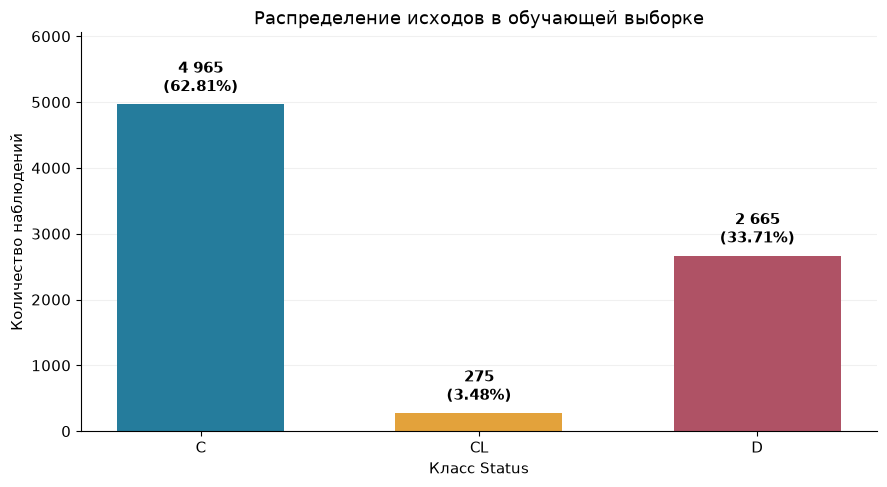

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(CLASSES, counts.values, color=['#257C9C', '#E3A23B', '#AF5265'], width=0.6)
for bar, count, share in zip(bars, counts.values, shares.values):
    label = f'{count:,}'.replace(',', ' ') + f'\n({share:.2%})'
    ax.text(bar.get_x() + bar.get_width()/2, count + counts.max()*0.025,
            label, ha='center', va='bottom', fontweight='bold')
ax.set(title='Распределение исходов в обучающей выборке',
       xlabel='Класс Status', ylabel='Количество наблюдений', ylim=(0, counts.max()*1.22))
ax.spines[['top', 'right']].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.18)
fig.tight_layout()
plt.show()

### 6.3 Оценка дисбаланса
Отношение численности самого частого класса к самому редкому: **IR = n_max / n_min**. Дополнительно учитываем абсолютное число наблюдений редкого класса. Единого универсального порога «сильного дисбаланса» для всех задач нет.

Accuracy постоянного прогноза наиболее частого класса показывает, почему общей доли правильных ответов недостаточно. Это описательный ориентир на всей выборке, а не проверенная на отложенных данных модель.

In [20]:
majority = counts.idxmax()
minority = counts.idxmin()
imbalance_ratio = counts.max() / counts.min()
print(f'Самый частый класс: {majority} — {counts.max()} ({shares[majority]:.2%}).')
print(f'Самый редкий класс: {minority} — {counts.min()} ({shares[minority]:.2%}).')
print(f'Отношение {majority}/{minority}: {imbalance_ratio:.2f}:1.')
print(f'Отношение D/CL: {counts["D"] / counts["CL"]:.2f}:1.')
print(f'Accuracy постоянного прогноза {majority}: {shares[majority]:.2%}.')

Самый частый класс: C — 4965 (62.81%).
Самый редкий класс: CL — 275 (3.48%).
Отношение C/CL: 18.05:1.
Отношение D/CL: 9.69:1.
Accuracy постоянного прогноза C: 62.81%.


### 6.4 Демонстрация стратифицированного разбиения 80/20
Фиксируем random_state=42. Стратификация сохраняет близкие доли классов, но не устраняет дисбаланс. Отложенная часть выделяется из train.csv, конкурсный test.csv не используется для локальной оценки качества.

In [21]:
from sklearn.model_selection import train_test_split

train_idx, valid_idx = train_test_split(
    train.index, test_size=0.20, random_state=42, stratify=target
)
train_counts = target.loc[train_idx].value_counts().reindex(CLASSES, fill_value=0)
valid_counts = target.loc[valid_idx].value_counts().reindex(CLASSES, fill_value=0)
split_summary = pd.DataFrame({
    'Всего': counts,
    'Обучение, n': train_counts,
    'Обучение, %': train_counts / len(train_idx) * 100,
    'Валидация, n': valid_counts,
    'Валидация, %': valid_counts / len(valid_idx) * 100,
})
print(split_summary.to_string())
print(f'Обучение: {len(train_idx)}; валидация: {len(valid_idx)}.')
print('Данные не изменены. Разбиение показано для иллюстрации.')

        Всего  Обучение, n  Обучение, %  Валидация, n  Валидация, %
Status                                                             
C        4965         3972        62.81           993         62.81
CL        275          220         3.48            55          3.48
D        2665         2132        33.71           533         33.71
Обучение: 6324; валидация: 1581.
Данные не изменены. Разбиение показано для иллюстрации.


### 6.5 Представленность классов при пятифолдовой кросс-валидации
Демонстрация на всей исходной обучающей выборке.

In [22]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_counts = []
for fold, (_, fold_valid_idx) in enumerate(cv.split(train, target), start=1):
    current = target.iloc[fold_valid_idx].value_counts().reindex(CLASSES, fill_value=0)
    fold_counts.append({'Фолд': fold, **current.to_dict()})
print(pd.DataFrame(fold_counts).set_index('Фолд').to_string())

        C  CL    D
Фолд              
1     993  55  533
2     993  55  533
3     993  55  533
4     993  55  533
5     993  55  533


### 6.6 Вывод по рассчитанным данным

In [23]:
print(f'В обучающей выборке {len(train)} наблюдений. '
      f'Класс C: {counts["C"]} ({shares["C"]:.2%}); '
      f'CL: {counts["CL"]} ({shares["CL"]:.2%}); '
      f'D: {counts["D"]} ({shares["D"]:.2%}).')
print(f'Распределение неравномерно: класс {majority} встречается '
      f'в {imbalance_ratio:.2f} раза чаще класса {minority}. '
      'Дисбаланс следует учитывать при разбиении и оценке моделей.')
print(f'В демонстрационном разбиении в валидации остаётся '
      f'{valid_counts[minority]} наблюдений самого редкого класса. '
      'Небольшое число ошибок может заметно менять его метрики.')

В обучающей выборке 7905 наблюдений. Класс C: 4965 (62.81%); CL: 275 (3.48%); D: 2665 (33.71%).
Распределение неравномерно: класс C встречается в 18.05 раза чаще класса CL. Дисбаланс следует учитывать при разбиении и оценке моделей.
В демонстрационном разбиении в валидации остаётся 55 наблюдений самого редкого класса. Небольшое число ошибок может заметно менять его метрики.


## 7. Двумерный анализ

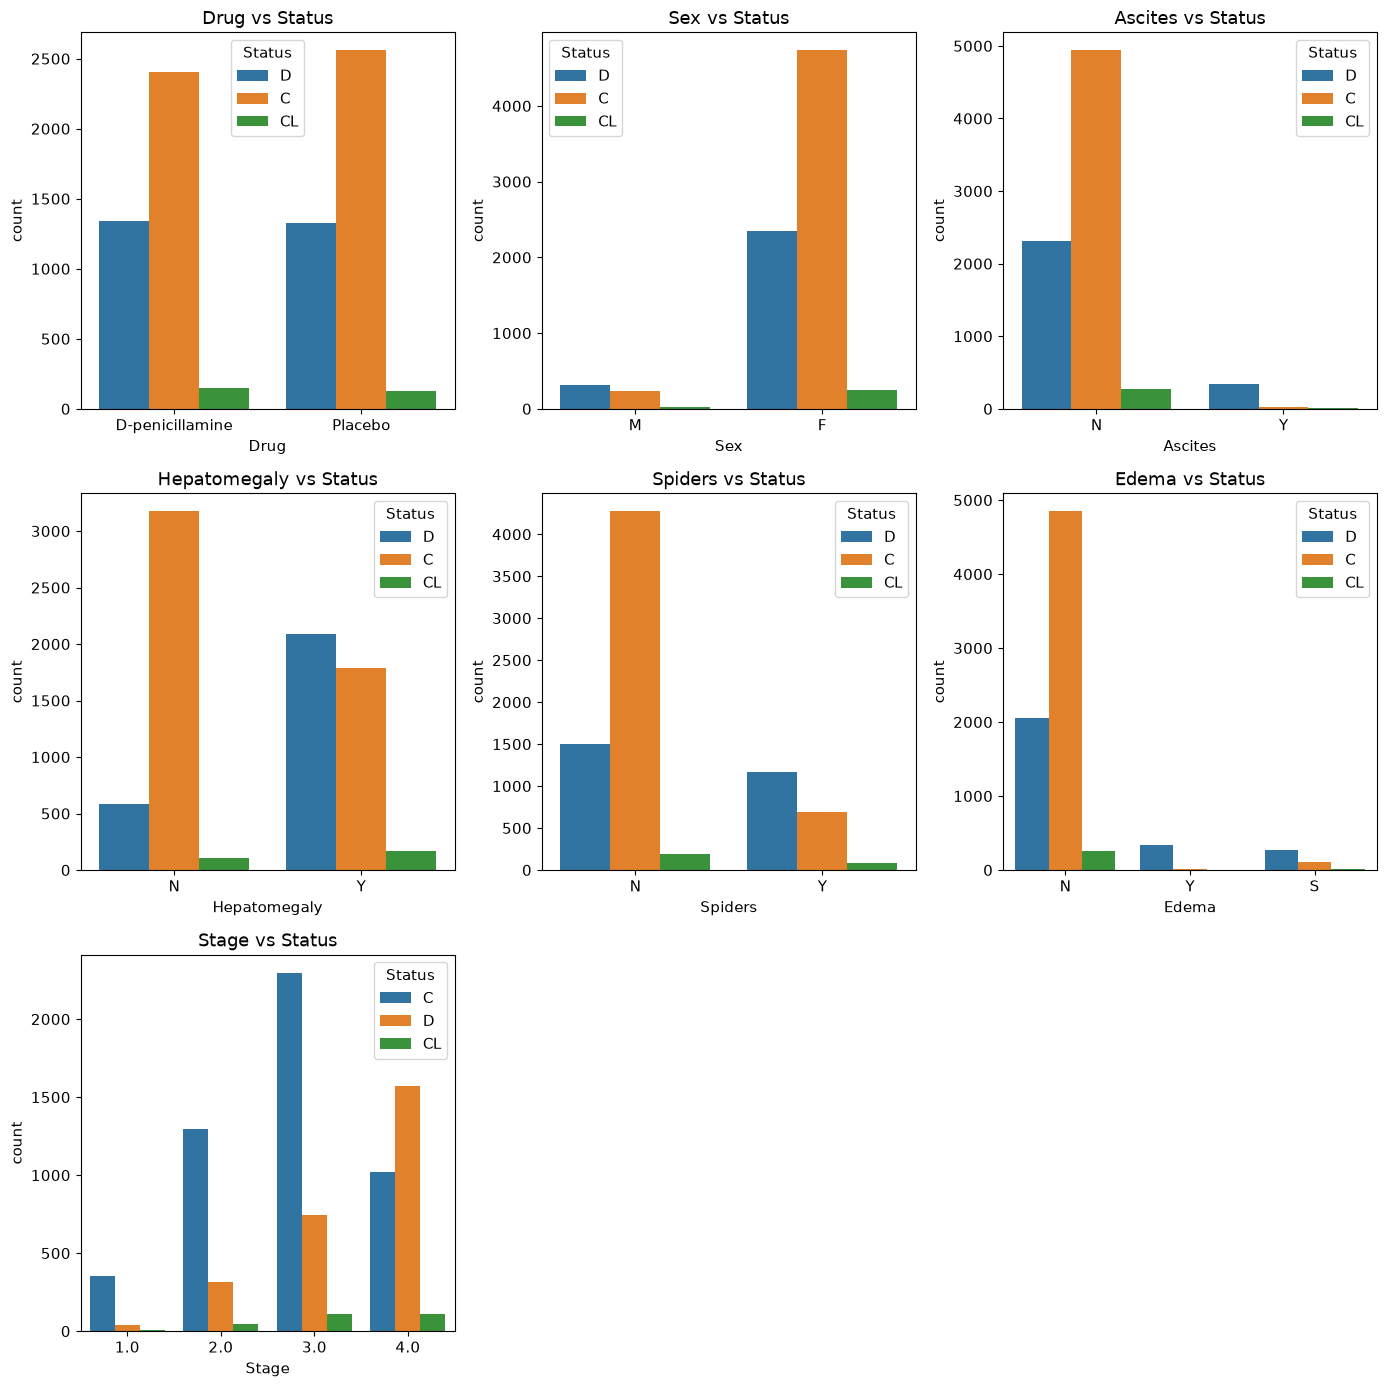

In [24]:
LABEL = 'Status'

plt.figure(figsize=(14, len(CAT_FEATS) * 2))
for i, col in enumerate(CAT_FEATS):
    plt.subplot(int(np.ceil(len(CAT_FEATS) / 3)), 3, i + 1)
    sns.countplot(x=col, hue=LABEL, data=train_clear)
    plt.title(f"{col} vs {LABEL}")
    plt.tight_layout()
plt.show()

In [25]:
bilirubin_by_sex = train_clear.groupby("Sex")["Bilirubin"].agg(
    Пациентов="count",
    Медиана="median",
    Среднее="mean",
    Q25=lambda s: s.quantile(0.25),
    Q75=lambda s: s.quantile(0.75)
)
display(bilirubin_by_sex)

,Пациентов,Медиана,Среднее,Q25,Q75
Sex,,,,,
F,7336,1.10,2.56,0.70,2.80
M,569,2.10,3.10,1.00,4.00


* В этой выборке медиана `Bilirubin` у мужчин выше, чем у женщин (2,1 против 1,1). Причины различия по данным EDA установить нельзя; качество модели для мужчин стоит оценивать отдельно.
* Распределения `Drug` по группам близки. Наличие или отсутствие эффекта лечения из этих графиков не следует; полезность признака для прогноза проверим на валидации.

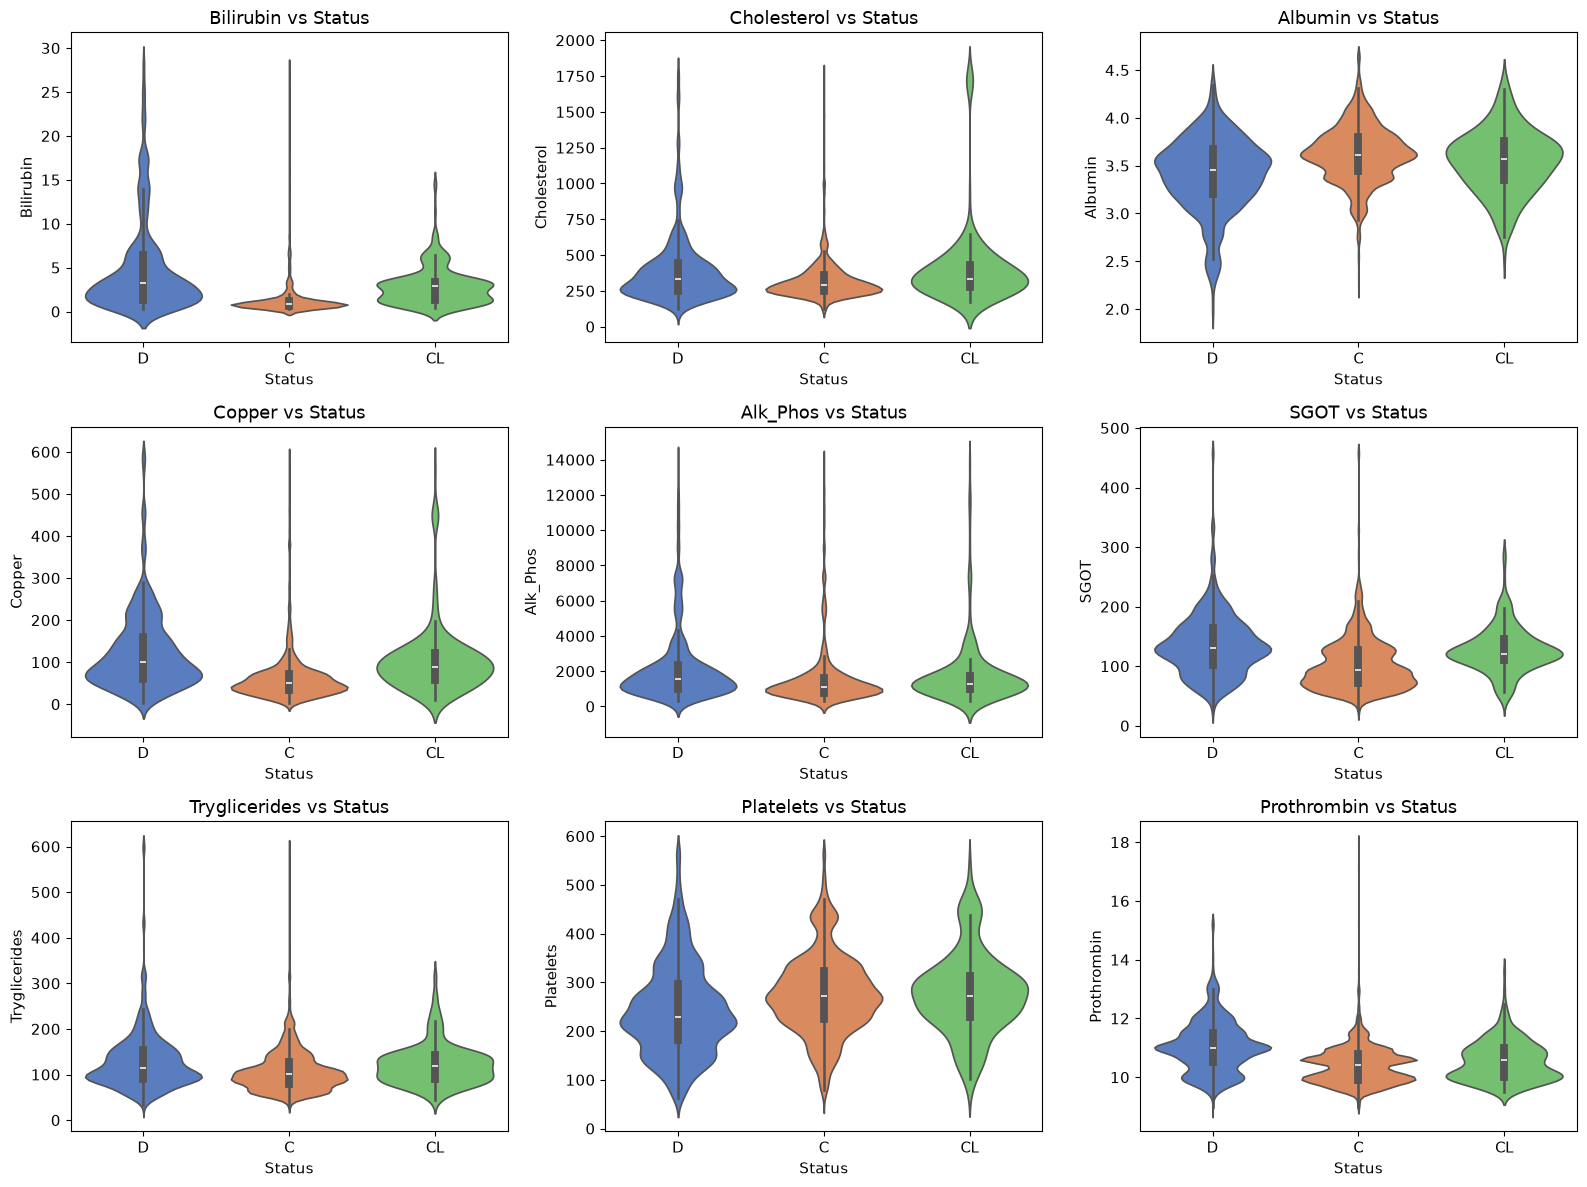

In [26]:
n = len(clean_num_feats)
ncols = 3
nrows = int(np.ceil(n / ncols)) 

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))

axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, clean_num_feats):
    sns.violinplot(x="Status", y=col, data=train_clear,
                   ax=ax, hue="Status", palette="muted", legend=False)
    ax.set_title(f"{col} vs Status")

for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [27]:
# Проверяем численность группы, прежде чем делать вывод по проценту.
edema_ascites_group = train_clear[
    (train_clear["Edema"] == "Y") & (train_clear["Ascites"] == "Y")
]
d_count = (edema_ascites_group["Status"] == "D").sum()
print(f"Edema=Y и Ascites=Y: {len(edema_ascites_group)} пациентов")
print(f"Статус D: {d_count} из {len(edema_ascites_group)} "
      f"({d_count / len(edema_ascites_group):.1%})")

Edema=Y и Ascites=Y: 244 пациентов
Статус D: 240 из 244 (98.4%)


* `Prothrombin`: возможный пороговый эффект около 10,7 секунды можно проверить при моделировании, сравнив модели с дополнительным пороговым признаком и без него.
* **Гипотеза:** `Stage` отражает стадию заболевания, а `Bilirubin` — текущий лабораторный показатель. Проверим, улучшает ли их взаимодействие прогноз по сравнению с использованием каждого признака отдельно.
* Различие значений `Bilirubin` между группами `Sex` не доказывает причинную роль пола; признак оцениваем на валидации.
* Полезность `Drug` проверим сравнением моделей с ним и без него.
* В группе `Edema=Y` и `Ascites=Y` статус `D` указан у 240 из 244 пациентов (98,4%). Это наблюдение для данной выборки; качество правила на остальных пациентах и на валидации пока неизвестно.

## 8. Корреляционный анализ

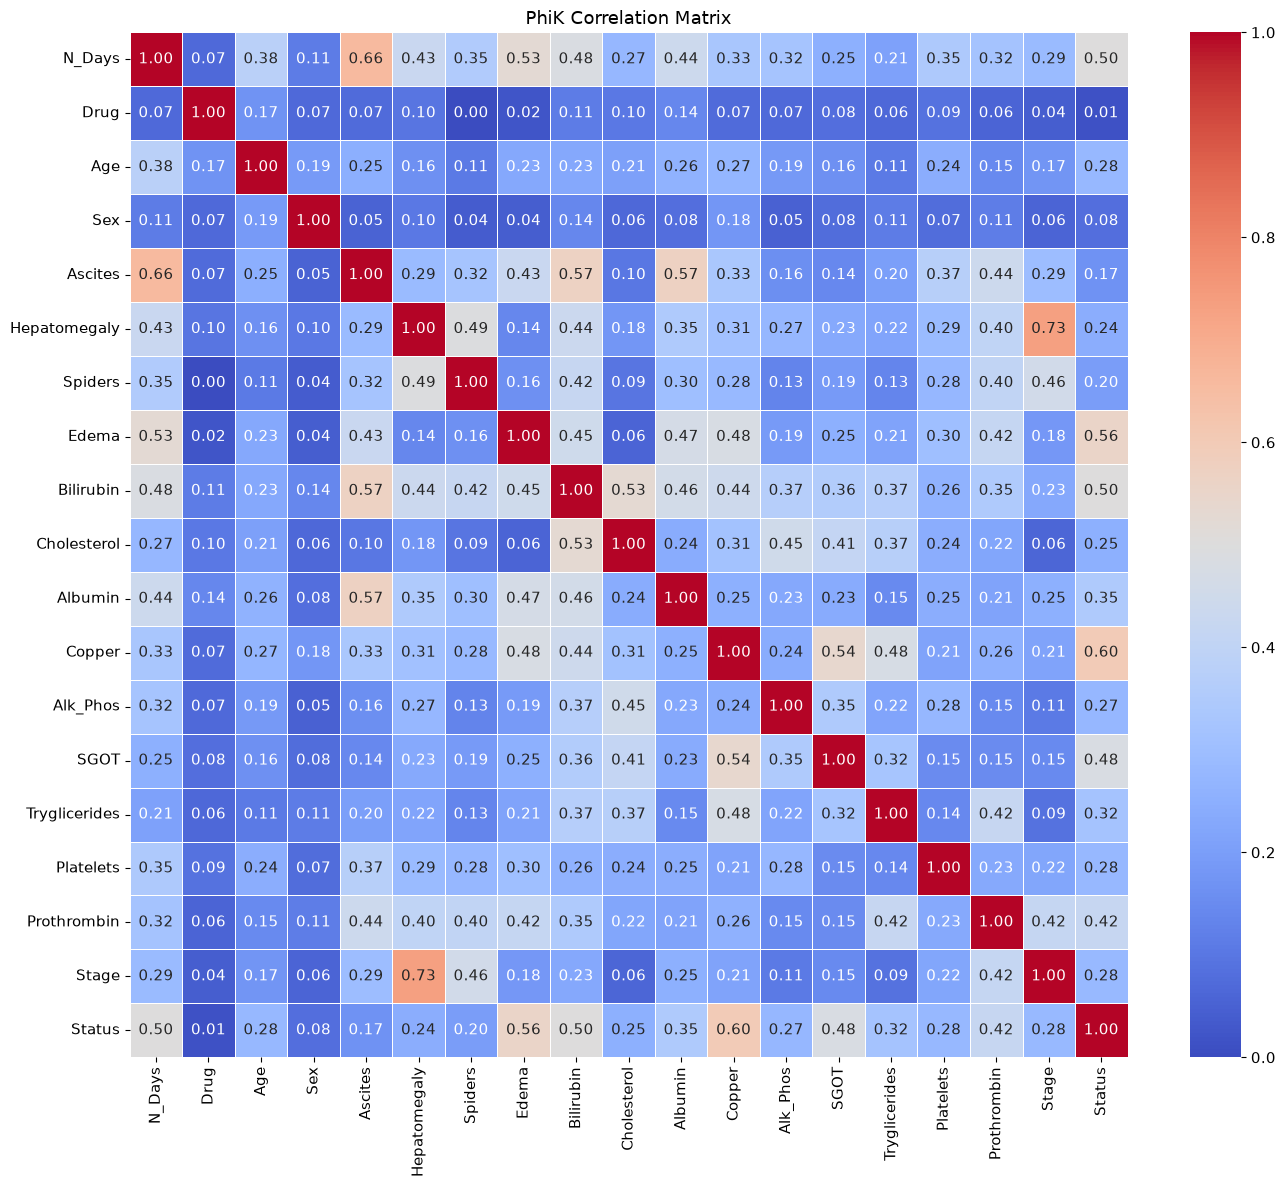

In [28]:
# PhiK позволяет исследовать связи между числовыми и категориальными признаками.
cols_for_corr = [column for column in train_clear.columns if column != "id"]
interval_cols = [
    column for column in train_clear.select_dtypes(include="number").columns
    if column != "Stage"
]
phik_matrix = phik.phik_matrix(train_clear[cols_for_corr], interval_cols=interval_cols)

plt.figure(figsize=(14, 12))
sns.heatmap(phik_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=0, vmax=1, linewidths=0.5)
plt.title("PhiK Correlation Matrix")
plt.tight_layout()
plt.show()

* Матрица PhiK показывает силу связей числовых и категориальных признаков. Коэффициенты PhiK не имеют знака, поэтому направление связи нужно проверять отдельно.
* **Гипотеза для моделирования:** связь `Drug` с `Status` по PhiK здесь около 0,01. Возможно, `Drug` можно исключить из признаков без ухудшения прогноза. Проверим это сравнением log loss моделей с `Drug` и без него на одних и тех же фолдах; низкий PhiK сам по себе не доказывает бесполезность признака.
* Для линейных моделей все категориальные признаки (бинарные Sex, Drug, Ascites, Spiders, Hepatomegaly, а также многоклассовые Edema и Stage) перед обучением целесообразно кодировать через OneHotEncoder(drop="first"): это переведёт бинарные признаки в формат 0/1, а для многоклассовых исключит строгую мультиколлинеарность.
* Для деревьев решений и градиентных бустингов числовые значения Stage и закодированные категории можно передавать напрямую без удаления базового уровня.


## 9. Гипотезы и инсайты для этапа машинного обучения

### 9.1 Анализ целевой переменной и качества данных
Выявлен выраженный дисбаланс классов: C встречается в 18,05 раза чаще CL (62,81% против 3,48%). Для сохранения пропорций классов при обучении следует использовать стратифицированную кросс-валидацию (StratifiedKFold, 5 фолдов). Также стоит проверить взвешивание классов (class_weight='balanced' или аналогичный механизм в выбранной модели).

Полных дубликатов в данных не обнаружено, поэтому удаление строк не требуется. Базовая Accuracy при прогнозе только наиболее частого класса составляет 62,81%, однако эта метрика не отражает качество распознавания редких классов. Для оценки моделей следует использовать multiclass log loss.

Отдельно стоит учитывать демографический перекос выборки: мужчины составляют всего 7,2% пациентов. На этапе валидации необходимо дополнительно проверить качество прогноза на мужской подгруппе, чтобы убедиться в отсутствии деградации модели на меньшинстве.

### 9.2 Анализ распределений и выбросов
Bilirubin, Cholesterol, Alk_Phos, Copper и Triglycerides имеют выраженную правую асимметрию. Экстремальные значения могут отражать реальные особенности состояния пациентов, поэтому удалять их автоматически не следует. Для линейных моделей и нейросетей можно проверить логарифмическое преобразование np.log1p.

Albumin имеет левую асимметрию. В подгруппе пациентов со значениями ниже нижней границы IQR существенно преобладают летальные исходы (Status = D), что указывает на высокую информативность низких значений альбумина для прогноза.

### 9.3 Категориальные признаки и кодирование
Категории Drug распределены практически поровну (50,7% и 49,3%), но равенство частот не показывает связь с целевой переменной. Полезность признака стоит проверить сравнением моделей с ним и без него.

Stage и Edema имеют упорядоченные категории, отражающие нарастание тяжести состояния. При обычном One-Hot Encoding информация о порядке уровней теряется, поэтому на валидации стоит сравнить One-Hot с порядковым кодированием (Ordinal Encoding: например, N=0, S=1, Y=2 для Edema и числовые значения 1–4 для Stage).

### 9.4 Генерация признаков
В группе Edema == 'Y' и Ascites == 'Y' статус D указан у 240 из 244 пациентов (98,4%). Это гипотеза для проверки бинарного признака edema_ascites_combination на валидации; по одной подгруппе качество модели неизвестно.

Гипотеза: Stage и Bilirubin могут дополнять друг друга при прогнозировании исхода. Проверим, улучшает ли признак Bilirubin * Stage качество на валидации; их сравнительная важность пока не установлена.

Дополнительно стоит проверить общий индекс клинических осложнений (суммарное количество присутствующих симптомов: Ascites, Hepatomegaly, Spiders и балл за Edema), так как накопление сразу нескольких признаков указывает на переход заболевания в стадию декомпенсации.

### 9.5 Интегральные медицинские шкалы
Альбумин, билирубин и протромбиновое время отражают разные аспекты функции печени. В качестве дополнительных признаков можно рассмотреть клинические показатели ALBI_score и Mayo_risk_score. Для их расчёта необходимо проверить единицы измерения и наличие всех необходимых переменных.

### 9.6 Методологические ограничения
N_Days связан с определением целевой переменной Status. Для конкурсной задачи Kaggle его использование допустимо в рамках заданной постановки. Однако для клинического прогноза на момент первичного обращения этот признак необходимо исключить, поскольку он содержит информацию о будущем периоде наблюдения и создаёт риск утечки данных (data leakage).

## 10. Протокол валидации и вспомогательные функции

В этом разделе один раз подготавливаем данные и фиксируем правила оценки, общие для всех последующих моделей.

Используем train_clear, созданный в EDA: в нём уже удалён технический столбец id. Целевой признак Status отделяем от матрицы признаков. Для всех моделей заранее фиксируем одни и те же пять стратифицированных фолдов (cv_splits).

Основная метрика — **Multiclass Log Loss**: она оценивает качество предсказанных вероятностей трёх классов. Дополнительно сохраняем Accuracy и Macro F1. Также рассчитываем наивную точку отсчёта: модель предсказывает априорные вероятности классов, рассчитанные только на обучающей части каждого фолда.

Функция evaluate_cv() будет использоваться для оценки всех следующих моделей. Это позволит сравнивать их на одинаковых разбиениях и не дублировать цикл кросс-валидации.

In [29]:
# Импорты для оценки и построения моделей
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

# train_clear создан в EDA: id уже удалён.
# Используем его, чтобы не создавать второй вариант очищенной таблицы.
X = train_clear.drop(columns=["Status"]).copy()
y = train_clear["Status"].copy()

# Проверяем целевой признак и порядок классов, зафиксированный в начале ноутбука.
if y.isna().any():
    raise ValueError("В целевом признаке Status обнаружены пропуски.")

if set(y.unique()) != set(CLASSES):
    raise ValueError(
        f"Ожидались классы {CLASSES}, получены {sorted(y.unique().tolist())}"
    )

# Материализуем разбиения один раз и далее используем их для всех моделей.
# cv - уже созданный в EDA объект StratifiedKFold.
cv_splits = list(cv.split(X, y))

folds_summary = []
for fold_number, (fold_train_idx, fold_valid_idx) in enumerate(cv_splits, start=1):
    train_counts_fold = (
        y.iloc[fold_train_idx].value_counts().reindex(CLASSES, fill_value=0)
    )
    valid_counts_fold = (
        y.iloc[fold_valid_idx].value_counts().reindex(CLASSES, fill_value=0)
    )

    folds_summary.append({
        "Фолд": fold_number,
        "Обучающих объектов": len(fold_train_idx),
        "Валидационных объектов": len(fold_valid_idx),
        **{
            f"Обучение: {class_name}": int(train_counts_fold[class_name])
            for class_name in CLASSES
        },
        **{
            f"Валидация: {class_name}": int(valid_counts_fold[class_name])
            for class_name in CLASSES
        },
    })

folds_summary_df = pd.DataFrame(folds_summary).set_index("Фолд")
display(folds_summary_df)

# Общий логгер результатов для всех моделей.
cv_results = []

,Обучающих объектов,Валидационных объектов,Обучение: C,Обучение: CL,Обучение: D,Валидация: C,Валидация: CL,Валидация: D
Фолд,,,,,,,,
1,6324,1581,3972,220,2132,993,55,533
2,6324,1581,3972,220,2132,993,55,533
3,6324,1581,3972,220,2132,993,55,533
4,6324,1581,3972,220,2132,993,55,533
5,6324,1581,3972,220,2132,993,55,533


**Выводы по блоку**

- cv_splits содержит конкретные индексы пяти фолдов. Все модели будут оцениваться на одних и тех же обучающих и валидационных частях.
- cv_results — общий список результатов. В него попадут метрики наивной модели и всех последующих алгоритмов.
- Разбиение стратифицированное: доли классов в каждом фолде близки к долям в исходной выборке.

### 10.1 Единая функция оценки моделей

Функция evaluate_cv() принимает подготовленный конвейер или модель, обучает его отдельно на каждом обучающем фолде, рассчитывает метрики на соответствующей валидационной части и добавляет результаты в общий логгер.

Порядок классов для Log Loss фиксируем через CLASSES. Перед расчётом вероятности при необходимости переставляются в этот порядок: это защищает от ошибки, если модель возвращает столбцы вероятностей в другом порядке.

In [45]:
import time

def evaluate_cv(pipeline, model_name, X_data, y_data, splits, results_list):
    """
    Оценивает модель на фиксированных фолдах
    и возвращает обновлённый DataFrame со всеми метриками.
    """
    if isinstance(results_list, pd.DataFrame):
        records = results_list.to_dict("records")
    else:
        records = list(results_list)

    # При повторном запуске ячейки удаляем старые записи этой же модели
    records = [r for r in records if r["Модель"] != model_name]

    for fold_num, (train_idx, valid_idx) in enumerate(splits, start=1):
        X_tr = X_data.iloc[train_idx]
        X_va = X_data.iloc[valid_idx]
        y_tr = y_data.iloc[train_idx]
        y_va = y_data.iloc[valid_idx]

        model = clone(pipeline)

        t0 = time.perf_counter()
        model.fit(X_tr, y_tr)
        fit_time = time.perf_counter() - t0

        t1 = time.perf_counter()
        probs = model.predict_proba(X_va)
        preds = model.predict(X_va)
        pred_time = time.perf_counter() - t1

        # Приводим столбцы predict_proba к единому порядку CLASSES
        model_classes = list(model.classes_)
        if set(model_classes) != set(CLASSES):
            raise ValueError(
                f"{model_name}, фолд {fold_num}: модель вернула классы "
                f"{model_classes}, ожидались {CLASSES}"
            )
        class_order = [model_classes.index(class_name) for class_name in CLASSES]
        probs = probs[:, class_order]

        records.append({
            "Модель": model_name,
            "Фолд": fold_num,
            "Log Loss": log_loss(y_va, probs, labels=CLASSES),
            "Accuracy": accuracy_score(y_va, preds),
            "Macro F1": f1_score(
                y_va,
                preds,
                labels=CLASSES,
                average="macro",
                zero_division=0
            ),
            "Fit Time (с)": fit_time,
            "Predict Time (с)": pred_time,
        })

    results_df = pd.DataFrame(records)
    current_model_results = (
        results_df[results_df["Модель"] == model_name]
        .reset_index(drop=True)
    )

    summary = current_model_results[
        ["Log Loss", "Accuracy", "Macro F1", "Fit Time (с)", "Predict Time (с)"]
    ].agg(["mean", "std"])

    display(current_model_results)
    display(summary)

    return results_df

Для каждой модели используется одна и та же функция и одни и те же фолды. `clone()` гарантирует, что обучение на одном фолде не переносится на следующий. В таблице сохраняются три метрики по каждому фолду. Сводка показывает среднее значение и стандартное отклонение. `Log Loss` нужно минимизировать, `Accuracy` и `Macro F1` — максимизировать. При выраженном дисбалансе классов Macro F1 и Log Loss информативнее одной Accuracy.

### 10.2 Наивная точка отсчёта: априорные вероятности классов

Сначала оценим простейшую модель без использования признаков. На каждом фолде она рассчитывает частоты классов только по обучающей части и возвращает эти частоты как вероятности для любого объекта валидации.

Для этого используем `DummyClassifier(strategy="prior")`. Такая оценка показывает, насколько хорошо можно справиться с задачей, просто зная распределение целевой переменной. Следующие модели должны превзойти эту точку отсчёта прежде, чем мы будем считать их полезными.

In [46]:
dummy_baseline = DummyClassifier(strategy="prior")

cv_results = evaluate_cv(
    dummy_baseline,
    "Naive baseline (class frequencies)",
    X,
    y,
    cv_splits,
    cv_results
)

,Модель,Фолд,Log Loss,Accuracy,Macro F1,Fit Time (с),Predict Time (с)
0,Naive baseline (class frequencies),1,0.78,0.63,0.26,0.00,0.00
1,Naive baseline (class frequencies),2,0.78,0.63,0.26,0.00,0.00
2,Naive baseline (class frequencies),3,0.78,0.63,0.26,0.01,0.00
3,Naive baseline (class frequencies),4,0.78,0.63,0.26,0.01,0.00
4,Naive baseline (class frequencies),5,0.78,0.63,0.26,0.01,0.00


,Log Loss,Accuracy,Macro F1,Fit Time (с),Predict Time (с)
mean,0.78,0.63,0.26,0.01,0.00
std,0.00,0.00,0.00,0.00,0.00


Наивная модель не анализирует признаки пациента: она выдаёт одинаковое для всех объектов распределение вероятностей, рассчитанное по обучающей части текущего фолда. Если следующая модель не улучшает Log Loss относительно наивной, значит, пока она не научилась извлекать из признаков полезную информацию о вероятностях классов.

## 11. Базовая модель: Logistic Regression (Baseline)

Теперь обучим первую базовую модель — многоклассовую логистическую регрессию на исходном наборе признаков (без генерации новых фич и нелинейных преобразований). Она станет отправной точкой для дальнейших экспериментов.

Для линейной модели числовые признаки стандартизируем с помощью StandardScaler. Все категориальные признаки (включая Stage, который представлен числами, но по смыслу является категорией) кодируем через OneHotEncoder(drop="first", handle_unknown="ignore"):
1) бинарные признаки (Sex, Drug, Ascites, Hepatomegaly, Spiders) автоматически преобразуются в один столбец 0/1;
2) многоклассовые (Edema, Stage) — в \(K - 1\) бинарных индикаторов относительно базовой категории.

Удаление первой категории (drop="first") избавляет линейную модель от строгой мультиколлинеарности и делает коэффициенты интерпретируемыми.

Оценку проводим через общую функцию evaluate_cv(). Дополнительно собираем out-of-fold (OOF) предсказания, чтобы построить матрицу ошибок и проверить качество модели на редком классе CL и мужской подгруппе.


,Модель,Фолд,Log Loss,Accuracy,Macro F1,Fit Time (с),Predict Time (с)
0,Logistic Regression (Baseline),1,0.51,0.80,0.53,0.13,0.02
1,Logistic Regression (Baseline),2,0.54,0.79,0.52,0.10,0.01
2,Logistic Regression (Baseline),3,0.52,0.80,0.53,0.11,0.02
3,Logistic Regression (Baseline),4,0.53,0.80,0.52,0.09,0.02
4,Logistic Regression (Baseline),5,0.53,0.80,0.52,0.09,0.02


,Log Loss,Accuracy,Macro F1,Fit Time (с),Predict Time (с)
mean,0.53,0.80,0.52,0.10,0.02
std,0.01,0.01,0.01,0.02,0.00


Log Loss      Accuracy      Macro F1       \
                                       mean  std     mean  std     mean  std   
Модель                                                                         
Logistic Regression (Baseline)         0.53 0.01     0.80 0.01     0.52 0.01   
Naive baseline (class frequencies)     0.78 0.00     0.63 0.00     0.26 0.00   

                                   Fit Time (с)      Predict Time (с)       
                                           mean  std             mean  std  
Модель                                                                      
Logistic Regression (Baseline)             0.10 0.02             0.02 0.00  
Naive baseline (class frequencies)         0.01 0.00             0.00 0.00

Отчёт по классам (OOF):
              precision    recall  f1-score   support

           C      0.811     0.908     0.857      4965
          CL      0.000     0.000     0.000       275
           D      0.761     0.671     0.713      2665

    accuracy                          0.796      7905
   macro avg      0.524     0.526     0.523      7905
weighted avg      0.766     0.796     0.778      7905

Log Loss (все пациенты): 0.52690
Log Loss (мужчины, n=569): 0.77031


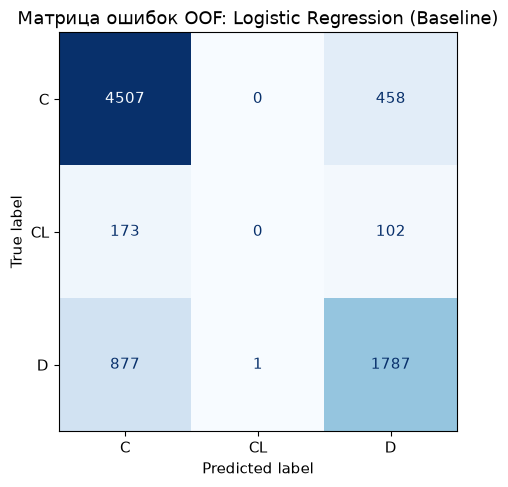

In [47]:
# Разделяем признаки на группы
logreg_cat_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Stage имеет числовое представление, но по смыслу является категорией.
if "Stage" in X.columns and "Stage" not in logreg_cat_features:
    logreg_cat_features.append("Stage")

logreg_num_features = [
    column
    for column in X.select_dtypes(include=np.number).columns
    if column not in logreg_cat_features
]

# Проверяем, что каждый признак попал ровно в одну группу.
if set(logreg_cat_features) & set(logreg_num_features):
    raise ValueError("Есть признаки, одновременно попавшие в две группы обработки.")

if set(logreg_cat_features) | set(logreg_num_features) != set(X.columns):
    raise ValueError("Не все признаки распределены между группами обработки.")

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), logreg_num_features),
        (
            "categorical",
            OneHotEncoder(drop="first"),
            logreg_cat_features
        ),
    ],
    remainder="drop"
)

logreg_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(max_iter=2000, random_state=42)
        ),
    ]
)

cv_results = evaluate_cv(
    logreg_pipeline,
    "Logistic Regression (Baseline)",
    X,
    y,
    cv_splits,
    cv_results
)

# Сводная таблица для сравнения наивной модели и логистической регрессии.
comparison_summary = (
    cv_results.groupby("Модель")[
        ["Log Loss", "Accuracy", "Macro F1", "Fit Time (с)", "Predict Time (с)"]
    ]
    .agg(["mean", "std"])
)
display(comparison_summary)

# Диагностика качества по классам и подгруппам на out-of-fold предсказаниях
oof_preds = pd.Series(index=X.index, dtype="object")
oof_probs = np.zeros((len(X), len(CLASSES)))

for train_idx, valid_idx in cv_splits:
    model_fold = clone(logreg_pipeline)
    model_fold.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof_preds.iloc[valid_idx] = model_fold.predict(X.iloc[valid_idx])

    probs_fold = model_fold.predict_proba(X.iloc[valid_idx])
    order = [list(model_fold.classes_).index(c) for c in CLASSES]
    oof_probs[valid_idx] = probs_fold[:, order]

print("Отчёт по классам (OOF):")
print(classification_report(y, oof_preds, labels=CLASSES, digits=3, zero_division=0))

male_mask = X["Sex"] == "M"
print(f"Log Loss (все пациенты): {log_loss(y, oof_probs, labels=CLASSES):.5f}")
print(f"Log Loss (мужчины, n={male_mask.sum()}): {log_loss(y[male_mask], oof_probs[male_mask], labels=CLASSES):.5f}")

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y, oof_preds, labels=CLASSES)
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Матрица ошибок OOF: Logistic Regression (Baseline)")
plt.tight_layout()
plt.show()

**Выводы по блоку**

Логистическая регрессия уверенно превосходит наивный базовый прогноз: средний Log Loss снизился с ~0.778 до ~0.52, выросли Accuracy и Macro F1. Признаки содержат выраженный сигнал для предсказания исходов. Как и ожидалось при дисбалансе 3,48%, модель хорошо разделяет частые классы C и D, но практически не предсказывает редкий класс CL по жёсткому порогу (низкий recall), хотя продолжает оценивать его вероятности для Log Loss.
